# Training

A U-Net with a ResNet34 encoder is trained on the tiles of notebook 02: seven Sentinel-2 scenes of 2020 spread over the seasons, 1,001 tiles of 384 pixels, six bands (blue, green, red, near infrared and the shortwave infrared bands B11 and B12).

The task is binary, PV against background. The encoder starts from ImageNet weights; geoai adapts its first layer to the six input bands.

## Setup

In [ ]:
import shutil
from pathlib import Path

import geoai

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
TRAINING_DIR = DATA_DIR / "training"
MODEL_DIR = BASE_DIR / "models"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"

NUM_CHANNELS = 6   # B02, B03, B04, B08, B11, B12
MODEL_FILE = "talatan_unet.pth"   # name used by notebook 04

for folder in (MODEL_DIR, EVALUATION_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## Train the Model

20 epochs with a batch size of 8. One fifth of the tiles is held back for validation. The checkpoint with the best validation score is kept as `best_model.pth`, which is the one used later.

In [ ]:
geoai.train_segmentation_model(
    images_dir=TRAINING_DIR / "images",
    labels_dir=TRAINING_DIR / "labels",
    output_dir=MODEL_DIR,
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=NUM_CHANNELS,
    num_classes=2,
    batch_size=8,
    num_epochs=20,
    learning_rate=0.001,
    val_split=0.2,
)

## Result

The curves show loss and the validation scores per epoch. Note that the IoU reported here is the mean over both classes, background included, so it is higher than the IoU against the hand labels in notebook 04.

The best checkpoint is then saved under its own name, so that a later training run cannot silently replace the model notebook 04 uses.

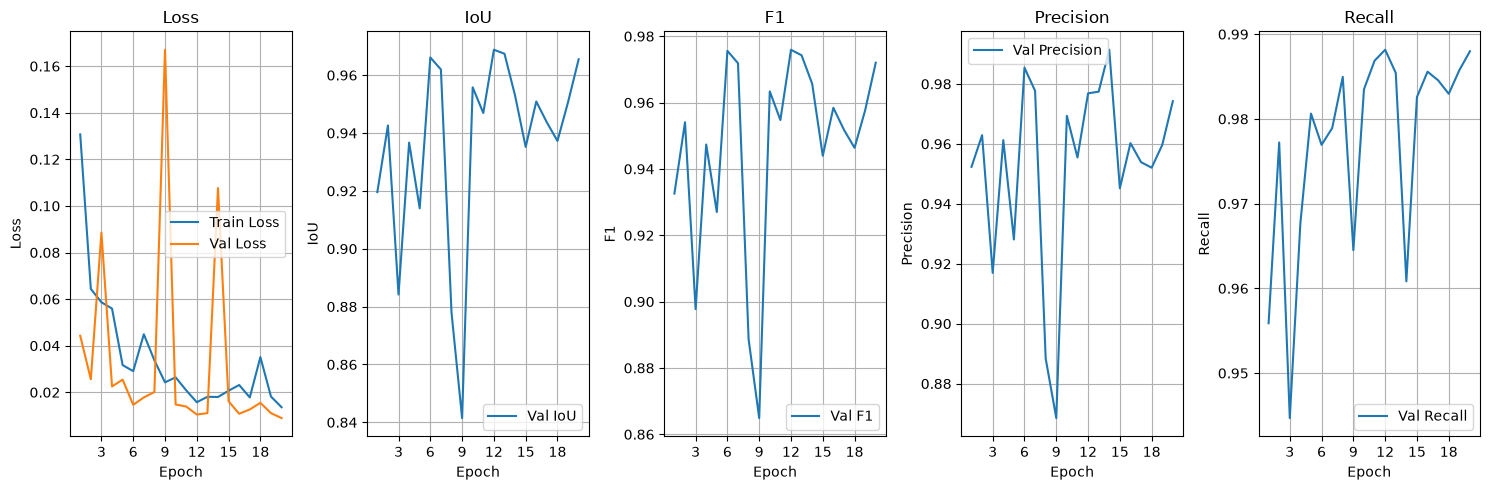


Saved as talatan_unet.pth

Training completed on: 2026-11-24 22:36:46
Architecture: unet
Encoder: resnet34
Total epochs: 20
Best validation IoU: 0.9688
Final validation IoU: 0.9655
Final validation F1: 0.9720
Final validation Precision: 0.9742
Final validation Recall: 0.9880
Final validation loss: 0.0089



In [ ]:
geoai.plot_performance_metrics(
    history_path=str(MODEL_DIR / "training_history.pth"),
    figsize=(15, 5),
)

shutil.copy(MODEL_DIR / "best_model.pth", MODEL_DIR / MODEL_FILE)
shutil.copy(MODEL_DIR / "training_summary.txt", EVALUATION_DIR / f"{Path(MODEL_FILE).stem}_summary.txt")

print(f"\nSaved as {MODEL_FILE}\n")
print((MODEL_DIR / "training_summary.txt").read_text())